In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, os.path.abspath(".."))   # lets this notebook import from src/
from src.data import BIN_MS, load_dataset, get_trials, build_features

DATA_PATH = "../data/000140/sub-Jenkins/"
MAX_HISTORY_BINS = 10                       # up to 10 bins x 20 ms = 200 ms of spike history
os.makedirs("../figures", exist_ok=True)

In [3]:
dataset = load_dataset(DATA_PATH)
trials = get_trials(dataset, history_ms=MAX_HISTORY_BINS * BIN_MS)

trial_ids = np.unique(trials["trial_id"])
print("neurons:", trials["spikes"].shape[1], "| trials:", len(trial_ids))
print("bins in the decoding window:", int((~trials["margin"]).sum()),
      "| extra history bins:", int(trials["margin"].sum()))

neurons: 142 | trials: 100
bins in the decoding window: 3500 | extra history bins: 2000


In [4]:
rng = np.random.default_rng(0)                         # fixed seed: the same split every run
test_ids = rng.choice(trial_ids, size=20, replace=False)
train_ids = np.setdiff1d(trial_ids, test_ids)
print(len(train_ids), "training trials |", len(test_ids), "test trials")

80 training trials | 20 test trials


In [5]:
X_all, y, groups, t_ms = build_features(trials, n_lags=MAX_HISTORY_BINS)
n_neurons = trials["spikes"].shape[1]
train = np.isin(groups, train_ids)        # True for bins from training trials
test = ~train
print("X:", X_all.shape, f"= {n_neurons} neurons x {MAX_HISTORY_BINS + 1} bins (current + {MAX_HISTORY_BINS} earlier)")
print("y:", y.shape, "| training bins:", int(train.sum()), "| test bins:", int(test.sum()))

X: (3500, 1562) = 142 neurons x 11 bins (current + 10 earlier)
y: (3500, 2) | training bins: 2800 | test bins: 700


In [6]:
ALPHAS = np.logspace(-1, 5, 13)    # penalty strengths to try: 0.1 to 100,000

def fit_decoder(n_lags):
    # Fit a ridge decoder that sees the current bin plus n_lags earlier bins; score it on the test trials
    X = X_all[:, : n_neurons * (n_lags + 1)]

    model = make_pipeline(StandardScaler(), Ridge())
    search = GridSearchCV(model, {"ridge__alpha": ALPHAS},
                          cv=GroupKFold(n_splits=5), scoring="r2", n_jobs=-1)
    search.fit(X[train], y[train], groups=groups[train])

    alpha = search.best_params_["ridge__alpha"]
    if alpha in (ALPHAS[0], ALPHAS[-1]):
        print(f"  note: best alpha ({alpha:g}) is at the edge of the range tried; consider widening ALPHAS")

    pred = search.predict(X[test])
    r2_x, r2_y = r2_score(y[test], pred, multioutput="raw_values")
    return {"history_ms": n_lags * BIN_MS, "alpha": alpha, "cv_r2": search.best_score_,
            "test_r2_x": r2_x, "test_r2_y": r2_y, "test_r2": (r2_x + r2_y) / 2,
            "pred": pred, "y_test": y[test], "groups_test": groups[test], "t_test": t_ms[test]}

base = fit_decoder(n_lags=0)
print(f"No history: best alpha = {base['alpha']:g}")
print(f"Test R²: x = {base['test_r2_x']:.3f}, y = {base['test_r2_y']:.3f}, mean = {base['test_r2']:.3f}")

No history: best alpha = 1000
Test R²: x = 0.179, y = 0.086, mean = 0.133


In [7]:
history_bins = [0, 1, 2, 3, 4, 5, 7, 10]
results = [fit_decoder(n) for n in history_bins]

cols = ["history_ms", "alpha", "cv_r2", "test_r2_x", "test_r2_y", "test_r2"]
summary = pd.DataFrame([{c: r[c] for c in cols} for r in results])
print(summary.round(3).to_string(index=False))

best = max(results, key=lambda r: r["cv_r2"])          # chosen using training trials only
print(f"\nChosen history: {best['history_ms']} ms (highest cross-validated R²)")
if best["history_ms"] == max(summary["history_ms"]):
    print("  note: the longest history tried scored best; longer histories might help further")
print(f"Test R²: x = {best['test_r2_x']:.3f}, y = {best['test_r2_y']:.3f}, mean = {best['test_r2']:.3f}")

 history_ms    alpha  cv_r2  test_r2_x  test_r2_y  test_r2
          0 1000.000  0.136      0.179      0.086    0.133
         20 1000.000  0.223      0.260      0.149    0.204
         40 1000.000  0.287      0.307      0.189    0.248
         60 1000.000  0.336      0.344      0.211    0.277
         80 1000.000  0.379      0.384      0.237    0.310
        100 1000.000  0.413      0.414      0.258    0.336
        140 3162.278  0.482      0.503      0.347    0.425
        200 3162.278  0.574      0.585      0.424    0.505

Chosen history: 200 ms (highest cross-validated R²)
  note: the longest history tried scored best; longer histories might help further
Test R²: x = 0.585, y = 0.424, mean = 0.505


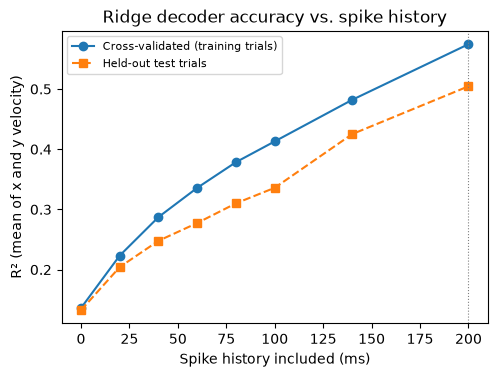

In [8]:
# Figure 5: decoding accuracy vs. how much spike history the model sees
plt.figure(figsize=(5.5, 3.8))
plt.plot(summary["history_ms"], summary["cv_r2"], "o-", label="Cross-validated (training trials)")
plt.plot(summary["history_ms"], summary["test_r2"], "s--", label="Held-out test trials")
plt.axvline(best["history_ms"], color="gray", lw=0.8, ls=":")
plt.xlabel("Spike history included (ms)")
plt.ylabel("R² (mean of x and y velocity)")
plt.title("Ridge decoder accuracy vs. spike history")
plt.legend(fontsize=8)
plt.savefig("../figures/05_r2_vs_history.png", dpi=150, bbox_inches="tight")

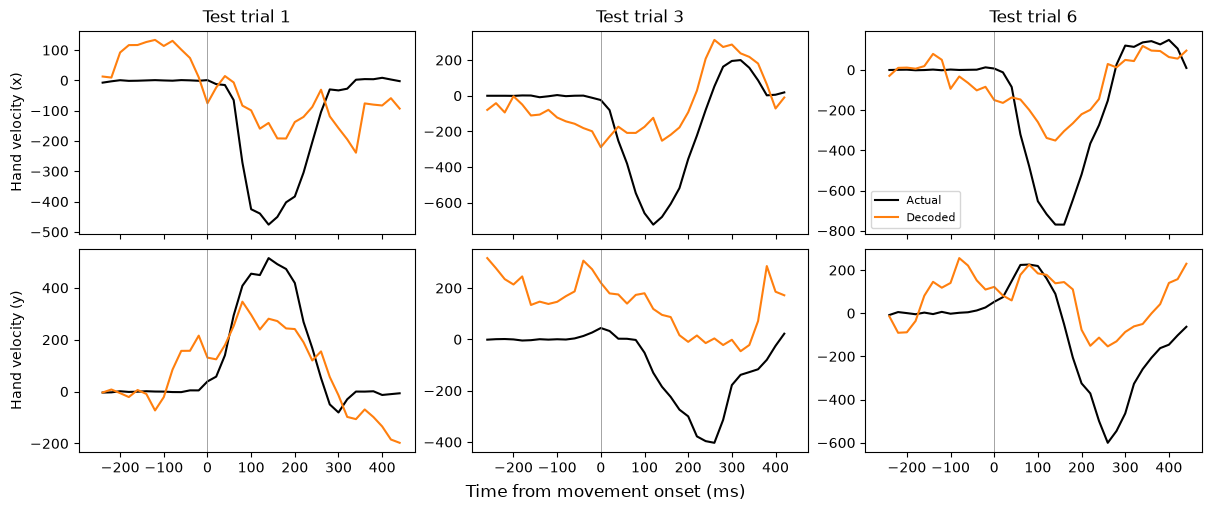

In [9]:
# Figure 6: decoded vs. actual hand velocity on three test trials
show_ids = np.unique(best["groups_test"])[:3]
fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharex=True, constrained_layout=True)
for col, tid in enumerate(show_ids):
    m = best["groups_test"] == tid
    for row, (name, k) in enumerate([("x", 0), ("y", 1)]):
        ax = axes[row, col]
        ax.plot(best["t_test"][m], best["y_test"][m, k], color="black", label="Actual")
        ax.plot(best["t_test"][m], best["pred"][m, k], color="tab:orange", label="Decoded")
        ax.axvline(0, color="gray", lw=0.5)
        if col == 0:
            ax.set_ylabel(f"Hand velocity ({name})")
        if row == 0:
            ax.set_title(f"Test trial {tid}")
axes[0, -1].legend(fontsize=8)
fig.supxlabel("Time from movement onset (ms)")
plt.savefig("../figures/06_decoded_velocity.png", dpi=150, bbox_inches="tight")

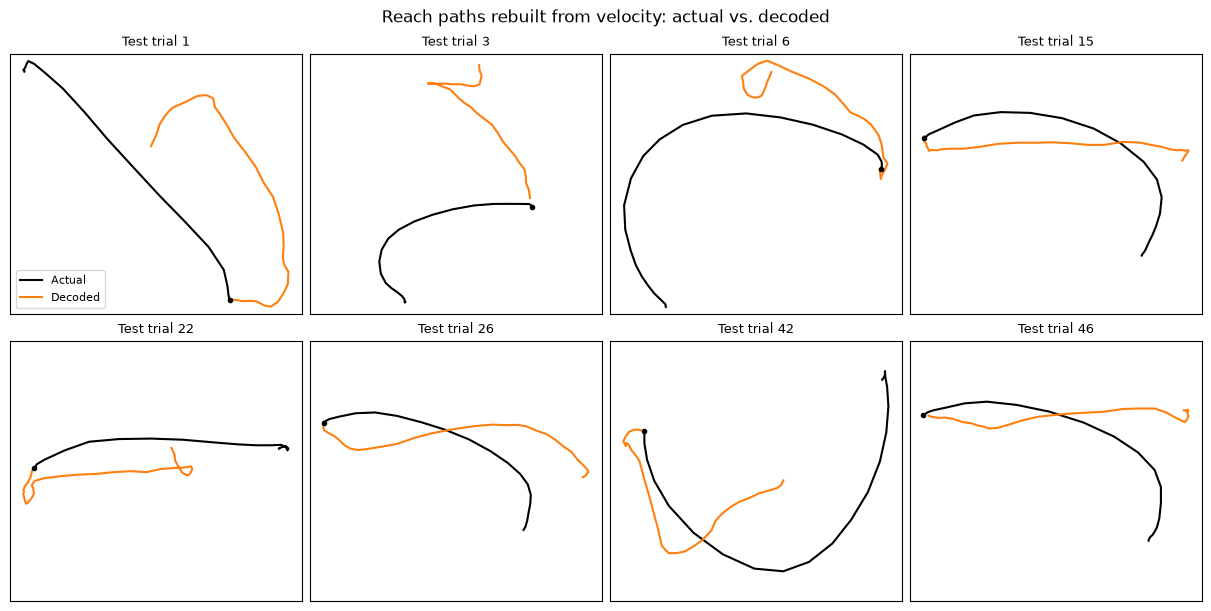

In [10]:
# Figure 7: reach paths rebuilt by adding up velocity over time, actual vs. decoded
dt = BIN_MS / 1000                                     # seconds per bin
path_ids = np.unique(best["groups_test"])[:8]
fig, axes = plt.subplots(2, 4, figsize=(12, 6), constrained_layout=True)
for ax, tid in zip(axes.flat, path_ids):
    m = best["groups_test"] == tid
    actual = np.cumsum(best["y_test"][m], axis=0) * dt
    decoded = np.cumsum(best["pred"][m], axis=0) * dt
    ax.plot(actual[:, 0], actual[:, 1], color="black", label="Actual")
    ax.plot(decoded[:, 0], decoded[:, 1], color="tab:orange", label="Decoded")
    ax.plot(0, 0, "o", color="black", ms=3)               # starting point
    ax.set_title(f"Test trial {tid}", fontsize=9)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xticks([]); ax.set_yticks([])
axes.flat[0].legend(fontsize=8)
fig.suptitle("Reach paths rebuilt from velocity: actual vs. decoded")
plt.savefig("../figures/07_decoded_paths.png", dpi=150, bbox_inches="tight")

In [11]:
print(f"Ridge decoder, {best['history_ms']} ms of spike history, {len(test_ids)} held-out trials: "
      f"R² = {best['test_r2']:.2f} (x = {best['test_r2_x']:.2f}, y = {best['test_r2_y']:.2f}), alpha = {best['alpha']:g}")

Ridge decoder, 200 ms of spike history, 20 held-out trials: R² = 0.50 (x = 0.59, y = 0.42), alpha = 3162.28
